In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

**Finding top peak signal for cycle 1 removed calls**

In [4]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_reconflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
cycle1_np_file = np.load(filename)
cycle1_biosample_inds_to_1 = cycle1_np_file['biosample_inds_to_1']
cycle1_DHS_inds_to_1 = cycle1_np_file['DHS_inds_to_1']
cycle1_biosample_inds_to_0 = cycle1_np_file['biosample_inds_to_0']
cycle1_DHS_inds_to_0 = cycle1_np_file['DHS_inds_to_0']

In [5]:
cycle1_flat_inds_removed = np.int64(cycle1_DHS_inds_to_0) + (n_DHSs * np.int64(cycle1_biosample_inds_to_0))
cycle1_flat_inds_added = np.int64(cycle1_DHS_inds_to_1) + (n_DHSs * np.int64(cycle1_biosample_inds_to_1))

In [22]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)
DHS_metadata['start'] = DHS_metadata['start'].astype(int)
DHS_metadata['end'] = DHS_metadata['end'].astype(int)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [3]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [ ]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [ ]:
del DHS_peak_signal_array

In [34]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [18]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [19]:
n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [32]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [27]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_reconflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
cycle1_np_file = np.load(filename)
cycle1_recon_flat = cycle1_np_file['recon_flat_array']

In [2]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

**Histogram of delta values**

In [12]:
len(cycle1_DHS_inds_to_1)

9746544

In [14]:
print(len(cycle1_recon_flat[cycle1_recon_flat<=0.0]))
print(len(cycle1_recon_flat[cycle1_recon_flat>=1.0]))

791817981
9746546


In [15]:
len(cycle1_recon_flat)

2632861234

In [17]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_reconflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
cycle1_np_file = np.load(filename)
cycle1_recon_flat = cycle1_np_file['recon_flat_array']

cycle1_recon_flat_for_plotting = cycle1_recon_flat
del cycle1_recon_flat

#values for bins of histogram
bins = np.round(np.arange(0, 3, 0.01), 3)
value_for_bins_cycle1 = np.zeros(300)
#counting and removing delta=0 values first since this is the majority of the data
mask = (cycle1_recon_flat_for_plotting>=bins[100]) & (cycle1_recon_flat_for_plotting<bins[101])
value_for_bins_cycle1[100] = len(cycle1_recon_flat_for_plotting[mask])
cycle1_recon_flat_for_plotting = cycle1_recon_flat_for_plotting[~mask]
for i in range(len(bins)-1):
    mask = (cycle1_recon_flat_for_plotting>=bins[i]) & (cycle1_recon_flat_for_plotting<bins[i+1])
    value_for_bins_cycle1[i] += len(cycle1_recon_flat_for_plotting[mask])
    cycle1_recon_flat_for_plotting = cycle1_recon_flat_for_plotting[~mask]
    
value_for_bins_cycle1 = value_for_bins_cycle1.astype(int)
del cycle1_recon_flat_for_plotting

Text(0.5, 1.0, 'Reconstruction Values for Every Call in Cycle 1\nReconstruction Threshold Flip, Threshold=0.0/1.0')

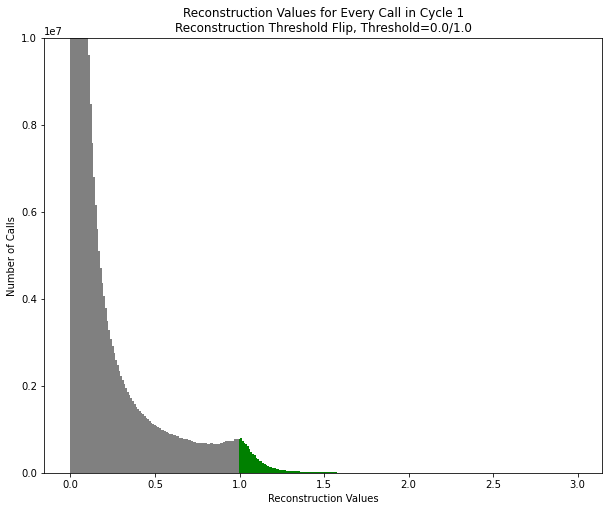

In [20]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.bar(bins[:100], value_for_bins_cycle1[:100], width=0.01, color='grey')
plt.bar(bins[100:], value_for_bins_cycle1[100:], width=0.01, color='green')
# plt.yscale('log')
plt.xlabel('Reconstruction Values')
plt.ylabel('Number of Calls')
plt.ylim([0, 10000000])
plt.title('Reconstruction Values for Every Call in Cycle 1\nReconstruction Threshold Flip, Threshold=0.0/1.0')

**Fraction of flipped peaks that have delta value of opposite polarity in neighboring DHS**

In [3]:
#find number of removed calls with an added call adjacent

cycle1_flat_inds_removed_set = set(removed_flat_inds_all_cycles[0])
cycle1_flat_inds_added_plus1_set = set(added_flat_inds_all_cycles[0]+1)
cycle1_flat_inds_added_minus1_set = set(added_flat_inds_all_cycles[0]-1)
len(cycle1_flat_inds_removed_set&cycle1_flat_inds_added_plus1_set) + len(cycle1_flat_inds_removed_set&cycle1_flat_inds_added_minus1_set)

4

In [4]:
#find number of added calls with an removed call adjacent

cycle1_flat_inds_added_set = set(added_flat_inds_all_cycles[0])
cycle1_flat_inds_removed_plus1_set = set(removed_flat_inds_all_cycles[0]+1)
cycle1_flat_inds_removed_minus1_set = set(removed_flat_inds_all_cycles[0]-1)
len(cycle1_flat_inds_added_set&cycle1_flat_inds_removed_plus1_set) + len(cycle1_flat_inds_added_set&cycle1_flat_inds_removed_minus1_set)

4

In [ ]:
#finding flat inds of neighboring DHSs to changed calls
cycle1_flipped_call_flat_inds = np.append(cycle1_flat_inds_added, cycle1_flat_inds_removed)
cycle1_flipped_call_flat_inds_1right = cycle1_flipped_call_flat_inds + 1
cycle1_flipped_call_flat_inds_2right = cycle1_flipped_call_flat_inds + 2
cycle1_flipped_call_flat_inds_1left = cycle1_flipped_call_flat_inds - 1
cycle1_flipped_call_flat_inds_2left = cycle1_flipped_call_flat_inds - 2

#finding delta vals for center DHS and neighbors
cycle1_flipped_call_flat_inds_left_to_right = np.array([cycle1_flipped_call_flat_inds_2left, 
                                                      cycle1_flipped_call_flat_inds_1left, 
                                                      cycle1_flipped_call_flat_inds,
                                                      cycle1_flipped_call_flat_inds_1right, 
                                                      cycle1_flipped_call_flat_inds_2right])
cycle1_flipped_call_recon_left_to_right = cycle1_recon_flat[cycle1_flipped_call_flat_inds_left_to_right]

In [19]:
#finding where center DHS and neighboring DHSs have opposite polarity in recon values
neg_thresh = 0.0
pos_thresh = 1.0
# cycle1_centerpos_neighborneg = ((cycle1_flipped_call_recon_left_to_right[2] > 0) & (cycle1_flipped_call_recon_left_to_right[0] < neg_thresh) | 
#                                (cycle1_flipped_call_recon_left_to_right[2] > 0) & (cycle1_flipped_call_recon_left_to_right[1] < neg_thresh) |
#                                (cycle1_flipped_call_recon_left_to_right[2] > 0) & (cycle1_flipped_call_recon_left_to_right[3] < neg_thresh) |
#                                (cycle1_flipped_call_recon_left_to_right[2] > 0) & (cycle1_flipped_call_recon_left_to_right[4] < neg_thresh))

# cycle1_centerneg_neighborpos = ((cycle1_flipped_call_recon_left_to_right[2] < 0) & (cycle1_flipped_call_recon_left_to_right[0] > pos_thresh) | 
#                                (cycle1_flipped_call_recon_left_to_right[2] < 0) & (cycle1_flipped_call_recon_left_to_right[1] > pos_thresh) |
#                                (cycle1_flipped_call_recon_left_to_right[2] < 0) & (cycle1_flipped_call_recon_left_to_right[3] > pos_thresh) |
#                                (cycle1_flipped_call_recon_left_to_right[2] < 0) & (cycle1_flipped_call_recon_left_to_right[4] > pos_thresh))

cycle1_centerpos_neighborneg = ((cycle1_flipped_call_recon_left_to_right[2] > 0) & (cycle1_flipped_call_recon_left_to_right[1] <= neg_thresh) |
                               (cycle1_flipped_call_recon_left_to_right[2] > 0) & (cycle1_flipped_call_recon_left_to_right[3] <= neg_thresh))

cycle1_centerneg_neighborpos = ((cycle1_flipped_call_recon_left_to_right[2] < 0) & (cycle1_flipped_call_recon_left_to_right[1] >= pos_thresh) |
                               (cycle1_flipped_call_recon_left_to_right[2] < 0) & (cycle1_flipped_call_recon_left_to_right[3] >= pos_thresh))

#inds relative to cycle1_flipped_call_flat_inds
cycle1_centerpos_neighborneg_inds = np.arange(len(cycle1_centerpos_neighborneg))[cycle1_centerpos_neighborneg]
cycle1_centerneg_neighborpos_inds = np.arange(len(cycle1_centerneg_neighborpos))[cycle1_centerneg_neighborpos]

print(np.sum(cycle1_centerpos_neighborneg.astype(int)))
print(np.sum(cycle1_centerneg_neighborpos.astype(int)))

4
4


In [20]:
#simulation to see how many randomly draw delta values acting as neighbors to added calls 
#are above/below some threshold 
count_list = []
for j in range(10):
    random_delta_list = np.array(random.choices(cycle1_diff_flat, k=len(cycle1_flat_inds_added)*2))
    split1 = random_delta_list[::2]
    split2 = random_delta_list[1::2]
    split1_hit_inds = np.where(split1 <= 0.0)[0]
    split2_hit_inds = np.where(split2 <= 0.0)[0]
    unique_hits = np.unique(np.append(split1_hit_inds, split2_hit_inds))
    count_list.append(len(unique_hits))
print(np.mean(count_list))
print(len(cycle1_flat_inds_added))

0.9
48879


In [21]:
#simulation to see how many randomly draw delta values acting as neighbors to removed calls 
#are above/below some threshold 
count_list = []
for j in range(10):
    random_delta_list = np.array(random.choices(cycle1_diff_flat, k=len(cycle1_flat_inds_removed)*2))
    split1 = random_delta_list[::2]
    split2 = random_delta_list[1::2]
    split1_hit_inds = np.where(split1 >= 1.0)[0]
    split2_hit_inds = np.where(split2 >= 1.0)[0]
    unique_hits = np.unique(np.append(split1_hit_inds, split2_hit_inds))
    count_list.append(len(unique_hits))
print(np.mean(count_list))
print(len(cycle1_flat_inds_removed))

0.7
22464


**Plotting signal tracks of reassignments**

In [30]:
#added flat inds that have adjacent removed flat inds
added_flat_inds_with_reassignment = list(cycle1_flat_inds_added_set&cycle1_flat_inds_removed_plus1_set)
added_flat_inds_with_reassignment.extend(list(cycle1_flat_inds_added_set&cycle1_flat_inds_removed_minus1_set))
added_flat_inds_with_reassignment = np.array(added_flat_inds_with_reassignment)
#corresponding removed flat inds
removed_flat_inds_with_reassignment = np.array(list(cycle1_flat_inds_added_set&cycle1_flat_inds_removed_plus1_set))-1
removed_flat_inds_with_reassignment = np.append(removed_flat_inds_with_reassignment, np.array(list(cycle1_flat_inds_added_set&cycle1_flat_inds_removed_minus1_set))+1)

added_biosample_inds_with_reassignment = added_flat_inds_with_reassignment // n_DHSs
added_DHS_inds_with_reassignment = added_flat_inds_with_reassignment % n_DHSs
removed_DHS_inds_with_reassignment = removed_flat_inds_with_reassignment % n_DHSs
added_DHS_inds_with_reassignment_chrm = np.array(DHS_metadata.loc[added_DHS_inds_with_reassignment]['seqname'])

In [55]:
def plotting_signal_overlapping_separate_panels(i, buffer=500, to0_threshold=0):
    #find biosample with call of interest
    biosample = added_biosample_inds_with_reassignment[i]
    #dhs of call of interest
    dhs = added_DHS_inds_with_reassignment[i]
    #chrm for DHS
    chrm = added_DHS_inds_with_reassignment_chrm[i]
#     dhss_inds_to_plot = DHS_inds_with_top_changes_left_to_right[:, i]
    #placing DHS of interest at the end
    dhss_inds_to_plot = np.append(dhs, removed_DHS_inds_with_reassignment[i])
    #presence or absence in original matrix
    dhss_to_plot_original_vals = cycle0_dhs_arr[biosample, dhss_inds_to_plot]
    #recon values of calls
    dhss_to_plot_recon_vals = cycle1_recon_flat[dhss_inds_to_plot + (biosample * n_DHSs)]
    dhs_of_interest_recon_val = cycle1_recon_flat[dhs + (biosample * n_DHSs)]
    #metadata for each DHS
    dhss_to_plot_df = DHS_metadata.loc[dhss_inds_to_plot]
    dhss_to_plot_comps = np.array(dhss_to_plot_df['component'])
    dhss_to_plot_comp_color = []
    for comp in dhss_to_plot_comps:
        comp_ind = np.where(comps==comp)[0]
        dhss_to_plot_comp_color.append(color[comp_ind][0])
    dhs_of_interest_name = np.array(DHS_metadata.loc[dhs]['identifier'])
    
    dhss_to_plot_start = np.array(DHS_metadata.loc[dhss_inds_to_plot]['start'])
    dhss_to_plot_end = np.array(DHS_metadata.loc[dhss_inds_to_plot]['end'])
    dhss_to_plot_summit = np.array(DHS_metadata.loc[dhss_inds_to_plot]['summit'])
    dhss_to_plot_names = np.array(DHS_metadata.loc[dhss_inds_to_plot]['identifier'])
    #placing DHS of interest in center
    first_dhs_start = dhss_to_plot_start[0]
    #not including DHS of interest
    last_dhs_end = dhss_to_plot_end[-2]
    
    dhs_of_interest_start = np.array(DHS_metadata.loc[dhs]['start'])
    dhs_of_interest_end = np.array(DHS_metadata.loc[dhs]['end'])
    
    dhs_of_interest_center = int((dhs_of_interest_start + dhs_of_interest_end)/2)
    max_dhs_dist_to_center = np.max([dhs_of_interest_center - first_dhs_start, last_dhs_end - dhs_of_interest_center])
    start = dhs_of_interest_center - buffer - max_dhs_dist_to_center
    end = dhs_of_interest_center + buffer + max_dhs_dist_to_center

    #load bw file for biosample of interest
    agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
    lnnum = biosample_df.loc[biosample]['Altius Library ID']
    if lnnum[-1].isalpha():
        lnnum = lnnum[:-1]
    read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
    # print(agnum)
    # print(lnnum)
    filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    
    read_in_question = bw_file.values(chrm, 
                                      start, 
                                      end, 
                                      numpy=True)
    
    
    positive_biosample_average_tracks = []
    negative_biosample_average_tracks = []
    positive_num_biosamples = []
    negative_num_biosamples = []
    for dhs_for_signal in dhss_inds_to_plot:
        
        #finding all biosamples positive for call of interest and removing biosample of interest 
        other_positive_biosamples = np.where(cycle0_dhs_arr[:, dhs_for_signal]==True)[0]
        other_positive_biosamples = other_positive_biosamples[other_positive_biosamples!=biosample]
        positive_num_biosamples.append(len(other_positive_biosamples))
        
        if len(other_positive_biosamples) > 0:
            #load bw file for all positive biosamples
            base_signal_values = []
            for base_biosample in other_positive_biosamples: 
                agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
                lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
                if lnnum[-1].isalpha():
                    lnnum = lnnum[:-1]
        #         base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
            #     print(agnum, lnnum)
                filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
                bw_file = pyBigWig.open(filename)
                base_read = bw_file.values(chrm, 
                                           start, 
                                           end, 
                                           numpy=True)
                base_signal_values.append(base_read)
            base_signal_values = np.array(base_signal_values)
            #bp average signal
            if len(other_positive_biosamples) > 1:
                base_signal_values_ave = np.nanmean(base_signal_values, axis=0)
            else:
                base_signal_values_ave = np.squeeze(base_signal_values)
        else:
            base_signal_values_ave = np.zeros(end-start)
            base_signal_values_ave[:] = np.nan
        positive_biosample_average_tracks.append(base_signal_values_ave)
        
        
        #finding all biosamples negative for call of interest 
        negative_biosamples = np.where(cycle0_dhs_arr[:, dhs_for_signal]==False)[0]
        negative_biosamples = negative_biosamples[negative_biosamples!=biosample]
        negative_num_biosamples.append(len(negative_biosamples))
        
        if len(negative_biosamples) > 0:
            #load bw file for all negative biosamples
            negative_signal_values = []
            for negative_biosample in negative_biosamples: 
                agnum = biosample_df.loc[negative_biosample]['Altius Aggregation ID'][2:]
                lnnum = biosample_df.loc[negative_biosample]['Altius Library ID']
                if lnnum[-1].isalpha():
                    lnnum = lnnum[:-1]
        #         negative_read_biosample_name = biosample_df.loc[negative_biosample]['Biosample name']
            #     print(agnum, lnnum)
                filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
                bw_file = pyBigWig.open(filename)
                negative_read = bw_file.values(chrm, 
                                               start, 
                                               end, 
                                               numpy=True)
                negative_signal_values.append(negative_read)
            negative_signal_values = np.array(negative_signal_values)
            #bp average signal
            if len(negative_biosamples) > 1:
                negative_signal_values_ave = np.nanmean(negative_signal_values, axis=0)
            else:
                negative_signal_values_ave = np.squeeze(negative_signal_values)
        else:
            negative_signal_values_ave = np.zeros(end-start)
            negative_signal_values_ave[:] = np.nan
        negative_biosample_average_tracks.append(negative_signal_values_ave)
    
    
    #plotting
    fig, axes = plt.subplots(nrows=len(dhss_inds_to_plot)+1, 
                             figsize=(10,8), 
                             gridspec_kw={'height_ratios': np.append(np.array([3]*len(dhss_inds_to_plot)), 2)})
    fig.patch.set_facecolor('white')
    
    for ind, ax in zip(range(len(dhss_inds_to_plot)), axes):
        ax.plot(np.arange(start, end), read_in_question, color='#17202A')
        ax.plot(np.arange(start, end), positive_biosample_average_tracks[ind], color=dhss_to_plot_comp_color[ind])
        ax.plot(np.arange(start, end), negative_biosample_average_tracks[ind], color=dhss_to_plot_comp_color[ind], alpha=0.4)
    
        

        ax.legend([read_in_question_biosample_name + ': ' + str(biosample), 
                    '%s Pos Biosamples Mean' %(positive_num_biosamples[ind]),
                    '%s Neg Biosamples Mean' %(negative_num_biosamples[ind])])
        ax.set_yscale('log')
        ax.set_ylabel('Signal', fontsize=12)
        ax.set_ylim([0.05, 9])
        if ind == 0:
            ax.set_title(r'$\alpha$ Signal Track (DHS: %s, %s)' %(dhss_to_plot_names[ind], dhss_to_plot_comps[ind]))
        elif ind == 1:
            ax.set_title(r'$\beta$ Signal Track (DHS: %s, %s)' %(dhss_to_plot_names[ind], dhss_to_plot_comps[ind]))
        else:
            ax.set_title(r'$\gamma$ Signal Track (DHS: %s, %s)' %(dhss_to_plot_names[ind], dhss_to_plot_comps[ind]))

        
    for ax, j in zip(axes, range(len(axes))):
        for ind in range(len(dhss_inds_to_plot)):
            if ind == 0:
                a=0.4
            else:
                a=0.2
            if ((ind == j) | (j == len(axes)-1)):
                ax.plot([dhss_to_plot_start[ind], dhss_to_plot_start[ind]], [0, 10], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
                ax.plot([dhss_to_plot_end[ind], dhss_to_plot_end[ind]], [0, 10], '--', color=dhss_to_plot_comp_color[ind], alpha=a)
        
        ax.set_xlim([start, end])
        ax.set_xticks([])
#         ax.set_xticks([start, int((end+start)/2), end])
#         ax.set_xticklabels([chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])
        
    axes[-1].set_ylim([0, 1])
    axes[-1].set_yticks([])
    axes[-1].set_xlabel('Genome', fontsize=12)
    axes[-1].set_xticks([start, int((end+start)/2), end])
    axes[-1].set_xticklabels([chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])
    axes[-1].set_title('DHS Track')
    
    for ind in range(len(dhss_inds_to_plot)):
        min_rect_base = 0.25
        if ind == 0:
            rect_base = min_rect_base
        else:
            rect_base = min_rect_base + 0.3
        if dhss_to_plot_original_vals[ind]:
            a = 1
        else:
            a = 0.25
        dhs_rect = patches.Rectangle((dhss_to_plot_start[ind], rect_base),
                                     dhss_to_plot_end[ind] - dhss_to_plot_start[ind], 
                                     0.2,
                                     alpha=a,
                                     color = dhss_to_plot_comp_color[ind])
        fig.gca().add_patch(dhs_rect)
        if ind == 0:
            plt.text(dhss_to_plot_start[ind]+10, rect_base-0.1, r'$\alpha$', fontsize=12)
        elif ind == 1:
            plt.text(dhss_to_plot_start[ind]+10, rect_base+0.25, r'$\beta$', fontsize=12)
        else:
            plt.text(dhss_to_plot_start[ind]+10, rect_base+0.25, r'$\gamma$', fontsize=12)
        
            
        
    for ind in range(len(dhss_inds_to_plot)):
        if ind == 0:
            arrow_base = 0.35
        else:
            arrow_base = 0.65
        
        adjustment = 0
        if dhss_to_plot_recon_vals[ind] <= to0_threshold:
            adjustment = 1
            
        axes[-1].arrow(dhss_to_plot_summit[ind], 
                  arrow_base, 
                  0, 
                  (dhss_to_plot_recon_vals[ind] - adjustment)/6, 
                  width=5, 
                  length_includes_head=False,
                  head_length=np.abs((dhss_to_plot_recon_vals[ind]-adjustment)/60))
        


    
    plot_title = 'Call Reassignment at DHS %s in Biosample %s\nReconstruction Threshold = 0.0/1.0' %(dhs_of_interest_name, read_in_question_biosample_name)
    print(plot_title)
    plt.suptitle(plot_title, fontsize=14)
    plt.show()

Call Reassignment at DHS 6.2856676 in Biosample fLeftVentricle
Reconstruction Threshold = 0.0/1.0


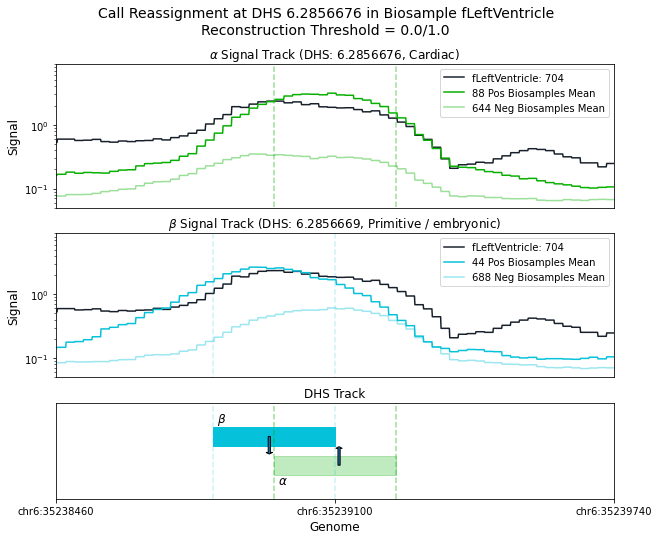

Call Reassignment at DHS 6.658879 in Biosample kidney_tubular
Reconstruction Threshold = 0.0/1.0


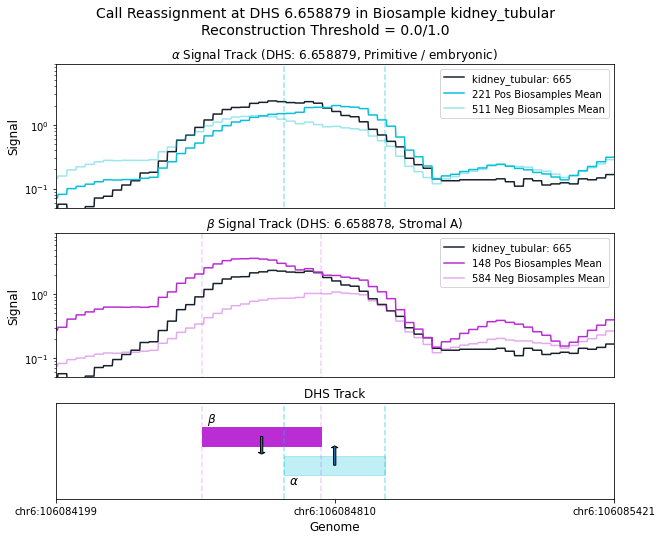

Call Reassignment at DHS 3.589862 in Biosample kidney_tubular
Reconstruction Threshold = 0.0/1.0


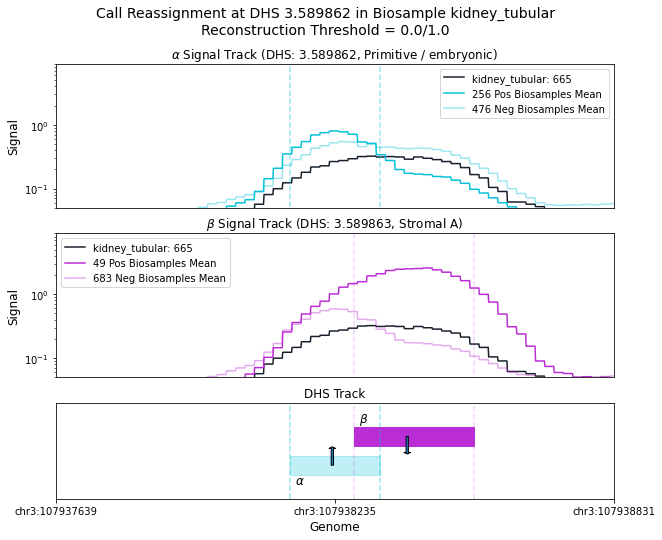

Call Reassignment at DHS 5.480734 in Biosample HIPEpiC
Reconstruction Threshold = 0.0/1.0


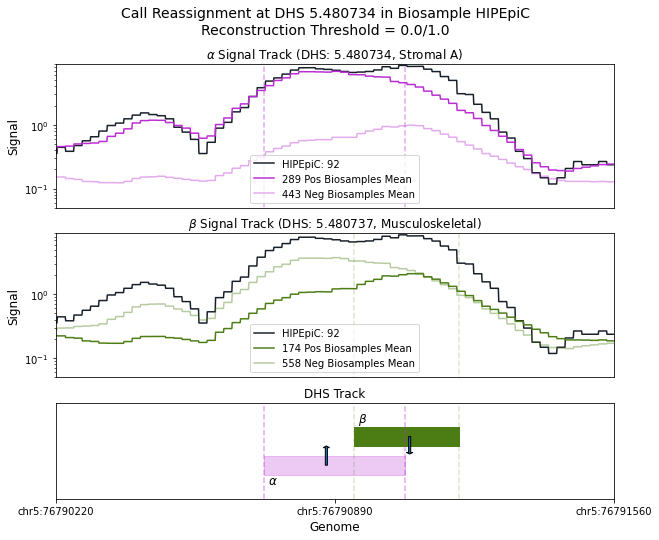

In [56]:
for i in range(4):
    plotting_signal_overlapping_separate_panels(i)